In [1]:
import torch
from torch import nn
from torchvision.datasets import CIFAR10
from torchvision import transforms
from torch.utils.data import Subset
import cv2
import matplotlib.pyplot as plt
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import classification_report
from skimage.feature import hog
from skimage import color
from tqdm import tqdm

In [2]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu'
print(f"device: {device}")

device: cuda


In [3]:
train_dataset = CIFAR10(
    root='../data/datasets/CIFAR10',
    train=True,
    download=True
)

In [4]:
data = train_dataset.data
mean = data.mean(axis=(0, 1, 2)) / 255.0
std = data.std(axis=(0, 1, 2)) / 255.0

In [5]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_dataset = CIFAR10(
    root='../data/datasets/CIFAR10',
    train=True,
    transform=transform,
    download=True
)
test_dataset = CIFAR10(
    root='../data/datasets/CIFAR10',
    train=False,
    transform=transform,
    download=False
)

In [6]:
id2label = {i: label for i, label in enumerate(train_dataset.classes)}
label2id = {label: i for i, label in enumerate(train_dataset.classes)}

In [7]:
def get_random_examples(n, dataset):
    idx = np.random.choice(len(test_dataset.targets), size=n, replace=False)
    examples = np.array(test_dataset.data[idx])
    labels = np.array(test_dataset.targets)[idx]
    return examples, labels

In [8]:
def predict_class(model, imgs, transform):
    model.eval()
    with torch.no_grad():
        transform_imgs = torch.stack([transform(img) for img in imgs]).to(device)
        
        outputs = nn.Softmax(dim=1)(model(transform_imgs))
        predict_classes = outputs.argmax(dim=1)
    return predict_classes


def draw_image_predicts(model, imgs, transform, true_classes):
    n = imgs.shape[0]
    cols = 8
    rows = int(torch.ceil(torch.tensor(n / cols)).item())
    classes = predict_class(model, imgs, transform).cpu()
    pred_labels = [id2label[i.item()] for i in classes]
    true_labels = [id2label[i] for i in true_classes]
    

    fig, axis = plt.subplots(rows, cols, figsize=(5*cols, 7*rows))
    axis = axis.flatten()

    for i in range(n):
        ax = axis[i]
        ax.imshow(imgs[i])
        ax.set_title(f'True: {true_labels[i]}\nPredict: {pred_labels[i]}', fontsize=30)
        ax.axis('off')

    for j in range(i+1, len(axis)):
        axis[j].axis('off')

    plt.tight_layout()

In [9]:
def train_loop(model, loss, optimizer, dataloader, train_losses):
    model.train()
    batch_losses = []
    all_targets = []
    all_predictions = []
    
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        optimizer.zero_grad()
        y_pred = model(X)
        output = loss(y_pred, y)
        batch_losses.append(output.item())
        output.backward()
        optimizer.step()

        all_predictions.extend(torch.argmax(y_pred, dim=1).cpu().tolist())
        all_targets.extend(y.cpu().tolist())

        if batch % 100 == 0:
            print(f'{(batch + 1) * dataloader.batch_size}/{len(dataloader) * dataloader.batch_size} | loss: {output.item()}')

    train_losses.append(sum(batch_losses) / len(batch_losses))

In [10]:
def test_loop(model, loss, dataloader, test_losses):
    model.eval()
    batch_losses = []
    all_targets = []
    all_predictions = []

    with torch.no_grad():
        for batch, (X, y) in enumerate(dataloader):
            X, y = X.to(device), y.to(device)
    
            y_pred = model(X)
            output = loss(y_pred, y)
            batch_losses.append(output.item())

    
            all_predictions.extend(torch.argmax(y_pred, dim=1).cpu().tolist())
            all_targets.extend(y.cpu().tolist())
    
        avg_loss = sum(batch_losses) / len(batch_losses)
        
        print(f'{"Test loss:":11} {avg_loss:.4f}')
        print(classification_report(all_targets, all_predictions))

    test_losses.append(sum(batch_losses) / len(batch_losses))

In [11]:
def train_test_loss_plot(train_losses, test_losses):
    plt.plot(range(1, num_epochs+1), train_losses, label='train loss')
    plt.plot(range(1, num_epochs+1), test_losses, label='test loss')
    plt.legend()
    plt.grid(alpha=0.6)
    plt.xlabel('epoch')
    plt.ylabel('loss')

In [12]:
def extract_hist_features(dataset):
    hist_features = []
    labels = []
    
    for i in tqdm(range(len(dataset))):
        img_pil, label = dataset[i]
        
              
        hist_features.append(hist_transform_func(img_pil))
        labels.append(label)
    
    return np.array(hist_features), np.array(labels)

def hist_transform_func(img):
    img_tensor = torch.tensor(np.array(img)).float() / 255.0
    img_tensor = img_tensor.permute(2, 0, 1)
    
    hists = []
    for j in range(3):
        hist = torch.histc(img_tensor[j], bins=256, min=0, max=1)
        hists.append(hist)
    return torch.cat(hists)

In [13]:
def extract_hog_features(dataset, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2)):
    hog_features = []
    labels = []
    
    for i in tqdm(range(len(dataset))):
        img_pil, label = dataset[i]
        
        img_np = np.array(img_pil)
        feat = hog_transform_func(img_np)
        hog_features.append(feat)
        labels.append(label)
    
    return np.array(hog_features), np.array(labels)

def hog_transform_func(img, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2)):  
    img_gray = color.rgb2gray(img)
    
    feat = hog(img_gray, 
               orientations=orientations, 
               pixels_per_cell=pixels_per_cell,
               cells_per_block=cells_per_block, 
               block_norm='L2-Hys')
    
    return torch.tensor(feat).float()

In [14]:
train_data = CIFAR10(root='../data/datasets/CIFAR10', train=True, download=True)
test_data = CIFAR10(root='../data/datasets/CIFAR10', train=False, download=True)

In [15]:
X_train_hist, y_train_hist = extract_hist_features(train_data)
X_test_hist, y_test_hist = extract_hist_features(test_data)

100%|██████████████████████████████████████████████████████████████████████████| 10000/10000 [00:03<00:00, 3127.10it/s]


In [16]:
X_train_hog, y_train_hog = extract_hog_features(train_data)
X_test_hog, y_test_hog = extract_hog_features(test_data)

100%|██████████████████████████████████████████████████████████████████████████| 10000/10000 [00:06<00:00, 1468.67it/s]


In [17]:
def data_to_dataloader(X_train, X_test, y_train, y_test, batch_size=128):
    X_train_tensor = torch.from_numpy(X_train).float()
    y_train_tensor = torch.from_numpy(y_train).long()
    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    
    X_test_tensor = torch.from_numpy(X_test).float()
    y_test_tensor = torch.from_numpy(y_test).long()
    test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

    return DataLoader(train_dataset, batch_size=batch_size), DataLoader(test_dataset, batch_size=batch_size)

In [18]:
# Получение рандомных картинок для демонстрации работы моделей
n = 16
examples, true_labels = get_random_examples(n, train_dataset)

# Задание 1. Old School Image Classification

# Задание 2. Классификация изображений полносвязной нейронной сетью

## Входные данные: пиксели

In [19]:
class ClassificationModel(nn.Module):
    def __init__(self, h=32, w=32, num_classes=10):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(3 * h * w, 512),
            nn.ReLU(),
            nn.BatchNorm1d(512),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.BatchNorm1d(512),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

In [20]:
batch_size = 128
train_dataloader = DataLoader(train_dataset, batch_size)
test_dataloader = DataLoader(test_dataset, batch_size)

In [21]:
model = ClassificationModel().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-5)
train_losses_fc = []
test_losses_fc = []

In [22]:
num_epochs = 5

In [23]:
for i in range(num_epochs):
    print(f'Epoch {i+1}')
    train_loop(model, loss_fn, optimizer, train_dataloader, train_losses_fc)
    test_loop(model, loss_fn, test_dataloader, test_losses_fc)
    print('-' * 30)

Epoch 1
128/50048 | loss: 2.488009452819824
12928/50048 | loss: 1.8369145393371582
25728/50048 | loss: 1.806164264678955
38528/50048 | loss: 1.7125070095062256
Test loss:  1.6570
              precision    recall  f1-score   support

           0       0.50      0.50      0.50      1000
           1       0.48      0.45      0.47      1000
           2       0.33      0.27      0.30      1000
           3       0.30      0.23      0.26      1000
           4       0.39      0.35      0.37      1000
           5       0.35      0.35      0.35      1000
           6       0.40      0.54      0.46      1000
           7       0.47      0.39      0.43      1000
           8       0.49      0.61      0.54      1000
           9       0.44      0.51      0.47      1000

    accuracy                           0.42     10000
   macro avg       0.42      0.42      0.42     10000
weighted avg       0.42      0.42      0.42     10000

------------------------------
Epoch 2
128/50048 | loss: 1.655

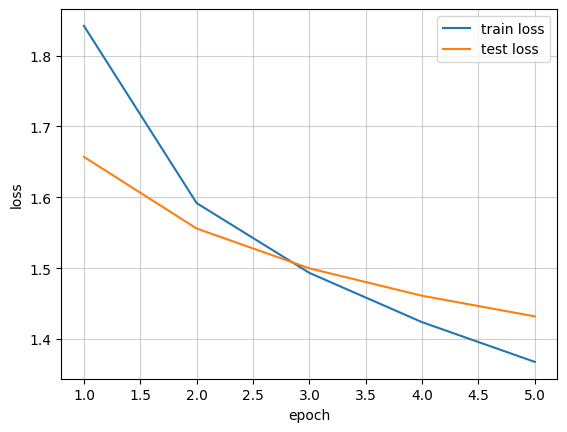

In [24]:
train_test_loss_plot(train_losses_fc, test_losses_fc)

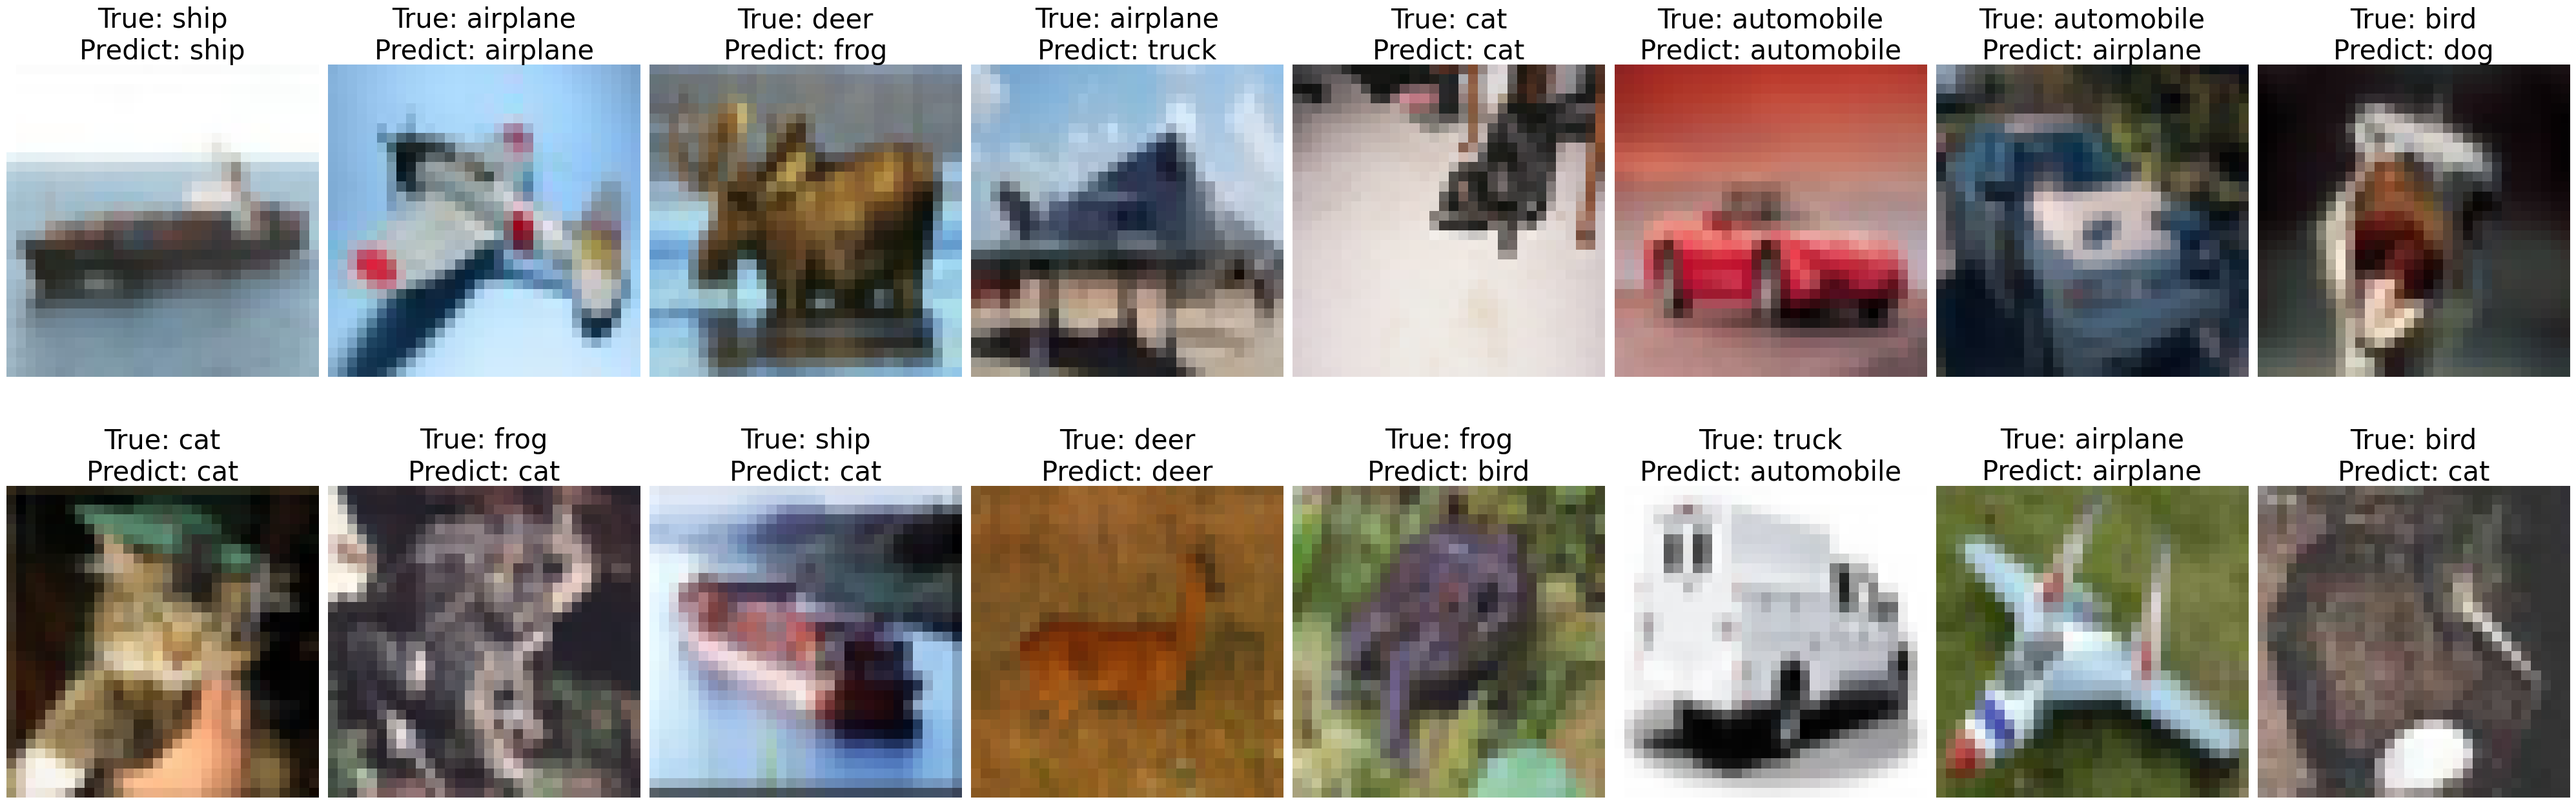

In [25]:
draw_image_predicts(model, examples, transform, true_labels)

## Входные данные: гистограммы

In [26]:
batch_size = 128
train_hist_dataloader, test_hist_dataloader = data_to_dataloader(X_train_hist, X_test_hist, y_train_hist, y_test_hist, batch_size)

In [27]:
class ClassificationHistModel(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(768, 512),
            nn.ReLU(),
            nn.BatchNorm1d(512),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.BatchNorm1d(512),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        logits = self.linear_relu_stack(x)
        return logits

In [28]:
hist_model = ClassificationHistModel().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(hist_model.parameters(), lr=1e-5)
train_losses_hist = []
test_losses_hist = []

In [29]:
num_epochs = 5

In [30]:
for i in range(num_epochs):
    print(f'Epoch {i+1}')
    train_loop(hist_model, loss_fn, optimizer, train_hist_dataloader, train_losses_hist)
    test_loop(hist_model, loss_fn, test_hist_dataloader, test_losses_hist)
    print('-' * 30)

Epoch 1
128/50048 | loss: 2.363651752471924
12928/50048 | loss: 2.195859432220459
25728/50048 | loss: 2.147770881652832
38528/50048 | loss: 2.0545096397399902
Test loss:  2.0391
              precision    recall  f1-score   support

           0       0.37      0.43      0.39      1000
           1       0.24      0.24      0.24      1000
           2       0.26      0.15      0.19      1000
           3       0.18      0.08      0.11      1000
           4       0.28      0.34      0.30      1000
           5       0.20      0.16      0.18      1000
           6       0.27      0.38      0.31      1000
           7       0.25      0.10      0.14      1000
           8       0.28      0.35      0.31      1000
           9       0.25      0.43      0.32      1000

    accuracy                           0.27     10000
   macro avg       0.26      0.27      0.25     10000
weighted avg       0.26      0.27      0.25     10000

------------------------------
Epoch 2
128/50048 | loss: 1.9929

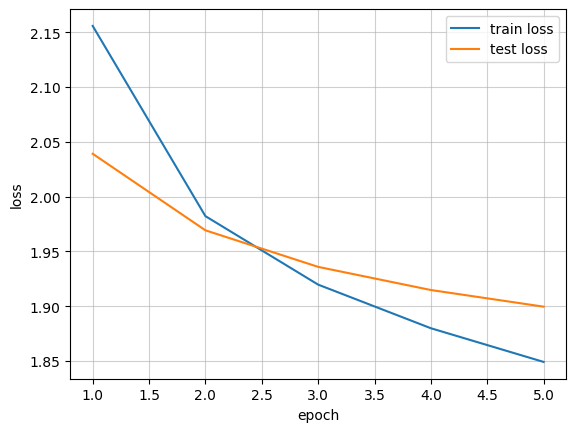

In [31]:
train_test_loss_plot(train_losses_hist, test_losses_hist)

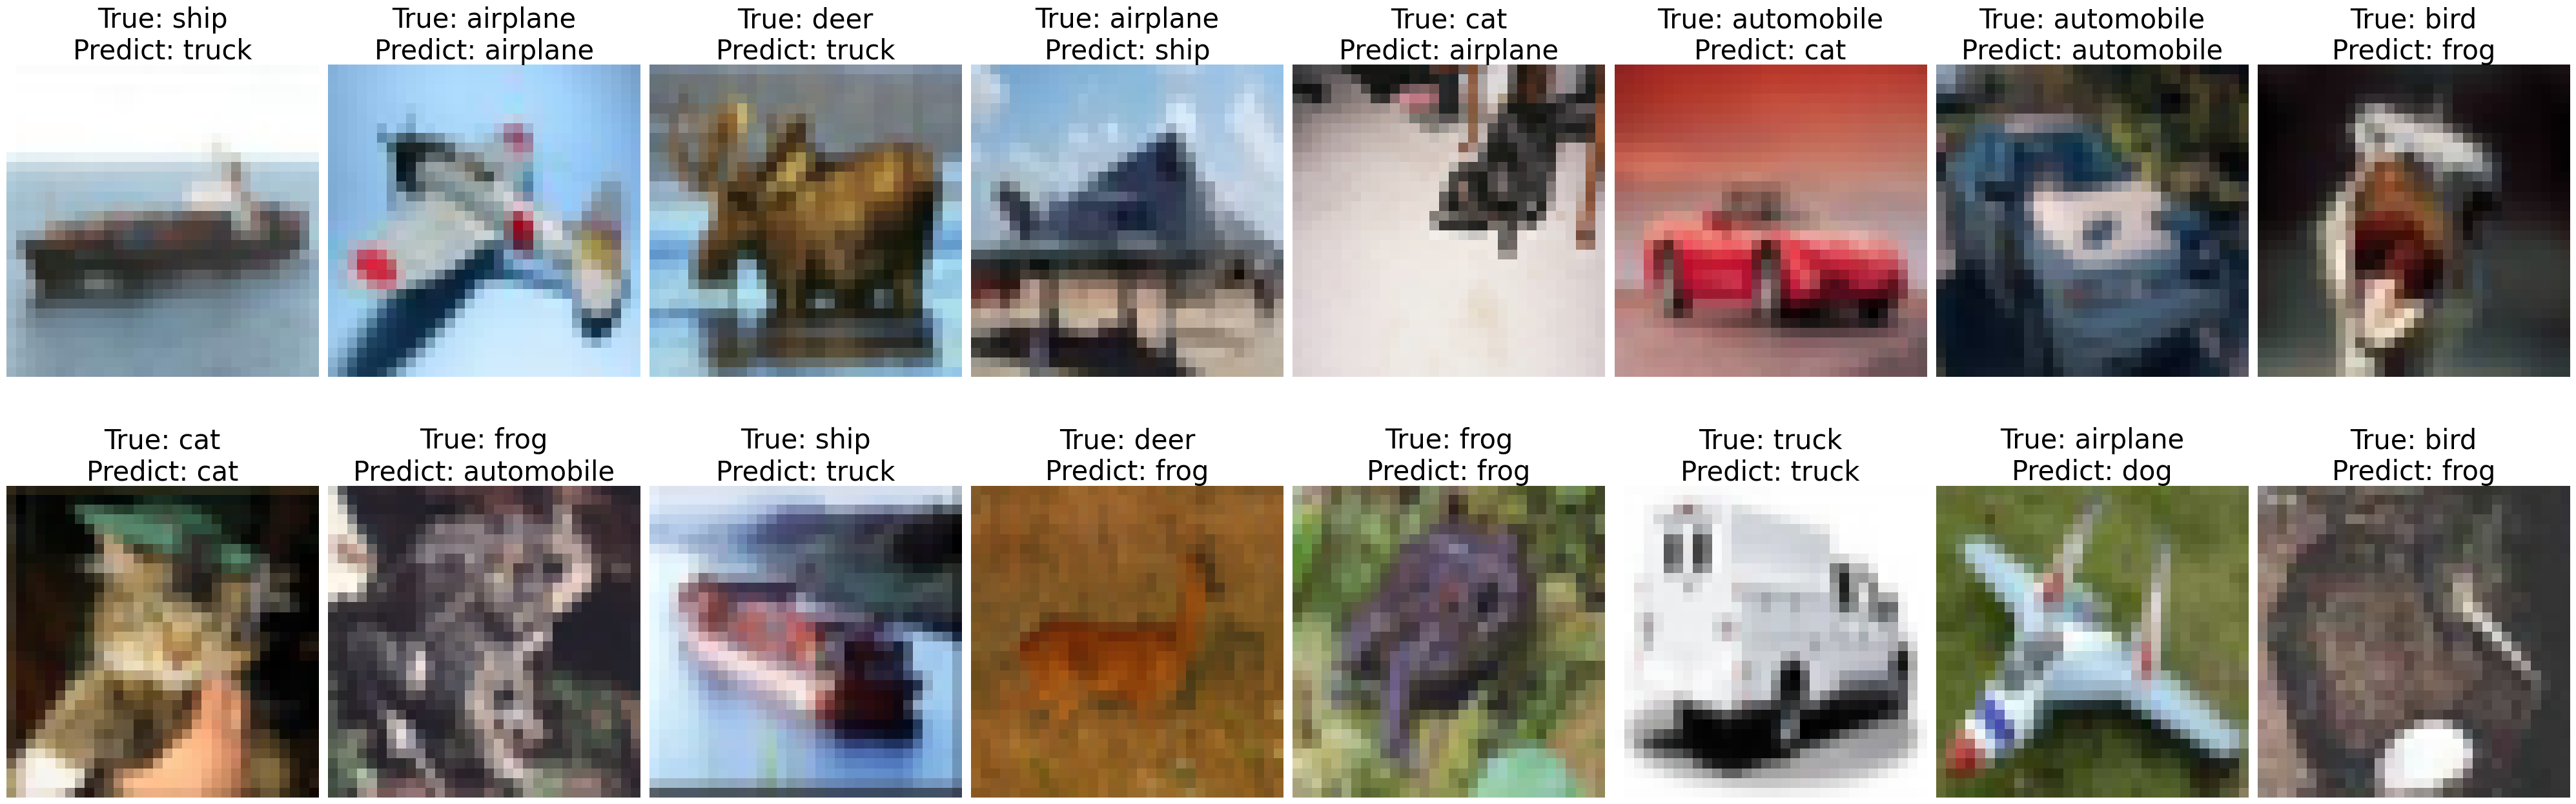

In [32]:
draw_image_predicts(hist_model, examples, hist_transform_func, true_labels)

## Входные данные: HOG

In [33]:
batch_size = 128
train_hog_dataloader, test_hog_dataloader = data_to_dataloader(X_train_hog, X_test_hog, y_train_hog, y_test_hog, batch_size)

In [34]:
class ClassificationHogModel(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(324, 512),
            nn.ReLU(),
            nn.BatchNorm1d(512),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.BatchNorm1d(512),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        logits = self.linear_relu_stack(x)
        return logits

In [35]:
hog_model = ClassificationHogModel().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(hog_model.parameters(), lr=1e-5)
train_losses_hog = []
test_losses_hog = []

In [36]:
num_epochs = 5

In [37]:
for i in range(num_epochs):
    print(f'Epoch {i+1}')
    train_loop(hog_model, loss_fn, optimizer, train_hog_dataloader, train_losses_hog)
    test_loop(hog_model, loss_fn, test_hog_dataloader, test_losses_hog)
    print('-' * 30)

Epoch 1
128/50048 | loss: 2.432490587234497
12928/50048 | loss: 2.06248140335083
25728/50048 | loss: 1.9005790948867798
38528/50048 | loss: 1.7615042924880981
Test loss:  1.7560
              precision    recall  f1-score   support

           0       0.45      0.51      0.48      1000
           1       0.48      0.45      0.47      1000
           2       0.36      0.22      0.27      1000
           3       0.27      0.17      0.20      1000
           4       0.32      0.25      0.28      1000
           5       0.31      0.40      0.35      1000
           6       0.34      0.57      0.43      1000
           7       0.44      0.35      0.39      1000
           8       0.42      0.48      0.45      1000
           9       0.48      0.50      0.49      1000

    accuracy                           0.39     10000
   macro avg       0.39      0.39      0.38     10000
weighted avg       0.39      0.39      0.38     10000

------------------------------
Epoch 2
128/50048 | loss: 1.7831

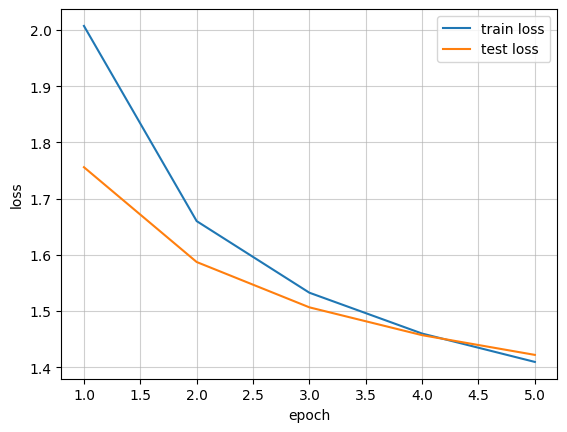

In [38]:
train_test_loss_plot(train_losses_hog, test_losses_hog)

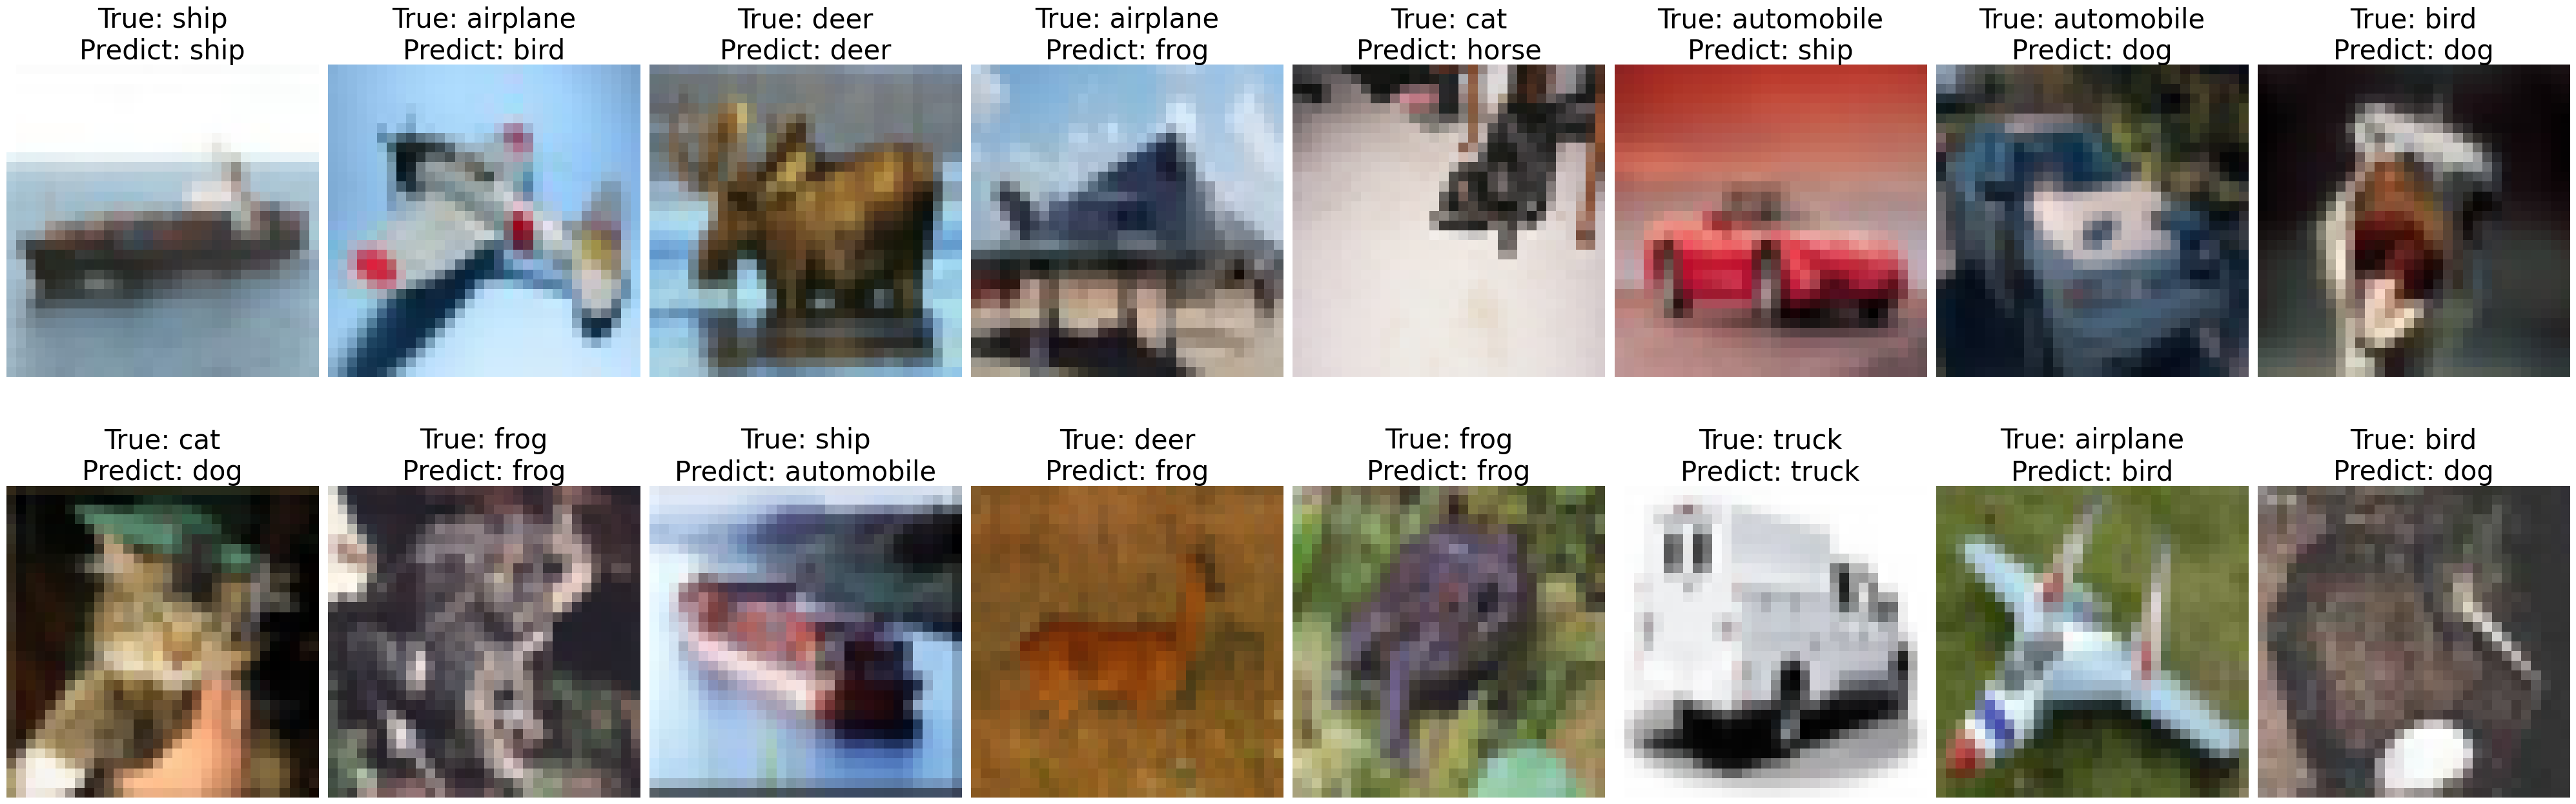

In [39]:
draw_image_predicts(hog_model, examples, hog_transform_func, true_labels)

# Задание 3. Классификация изображений сверточной нейросетью

In [40]:
class ConvClassificationModel(nn.Module):
    def __init__(self, h=32, w=32, num_classes=10):
        super().__init__()
        self.conv_stack = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(32),
            nn.MaxPool2d(2, 2)
        )
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(32 * (h // 2) * (w // 2), 512),
            nn.ReLU(),
            nn.BatchNorm1d(512),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.BatchNorm1d(512),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.conv_stack(x)
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

In [41]:
conv_model = ConvClassificationModel().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(conv_model.parameters(), lr=1e-5)
train_losses_conv = []
test_losses_conv = []

In [42]:
num_epochs = 5

In [43]:
for i in range(num_epochs):
    print(f'Epoch {i+1}')
    train_loop(conv_model, loss_fn, optimizer, train_dataloader, train_losses_conv)
    test_loop(conv_model, loss_fn, test_dataloader, test_losses_conv)
    print('-' * 30)

Epoch 1
128/50048 | loss: 2.468629837036133
12928/50048 | loss: 1.6099363565444946
25728/50048 | loss: 1.5646591186523438
38528/50048 | loss: 1.387687087059021
Test loss:  1.3881
              precision    recall  f1-score   support

           0       0.57      0.59      0.58      1000
           1       0.63      0.62      0.63      1000
           2       0.42      0.33      0.37      1000
           3       0.40      0.30      0.34      1000
           4       0.47      0.40      0.43      1000
           5       0.44      0.45      0.44      1000
           6       0.51      0.68      0.59      1000
           7       0.57      0.55      0.56      1000
           8       0.60      0.68      0.63      1000
           9       0.53      0.60      0.56      1000

    accuracy                           0.52     10000
   macro avg       0.51      0.52      0.51     10000
weighted avg       0.51      0.52      0.51     10000

------------------------------
Epoch 2
128/50048 | loss: 1.314

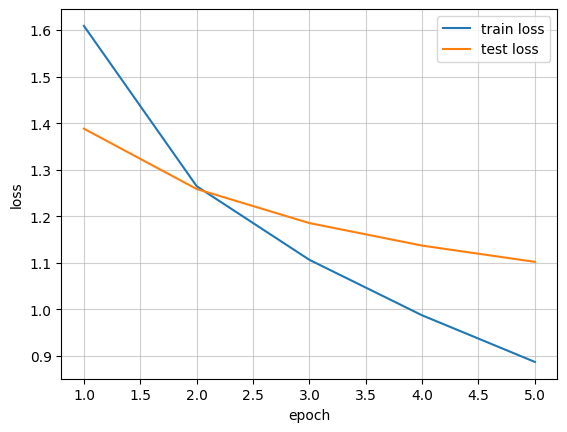

In [44]:
train_test_loss_plot(train_losses_conv, test_losses_conv)

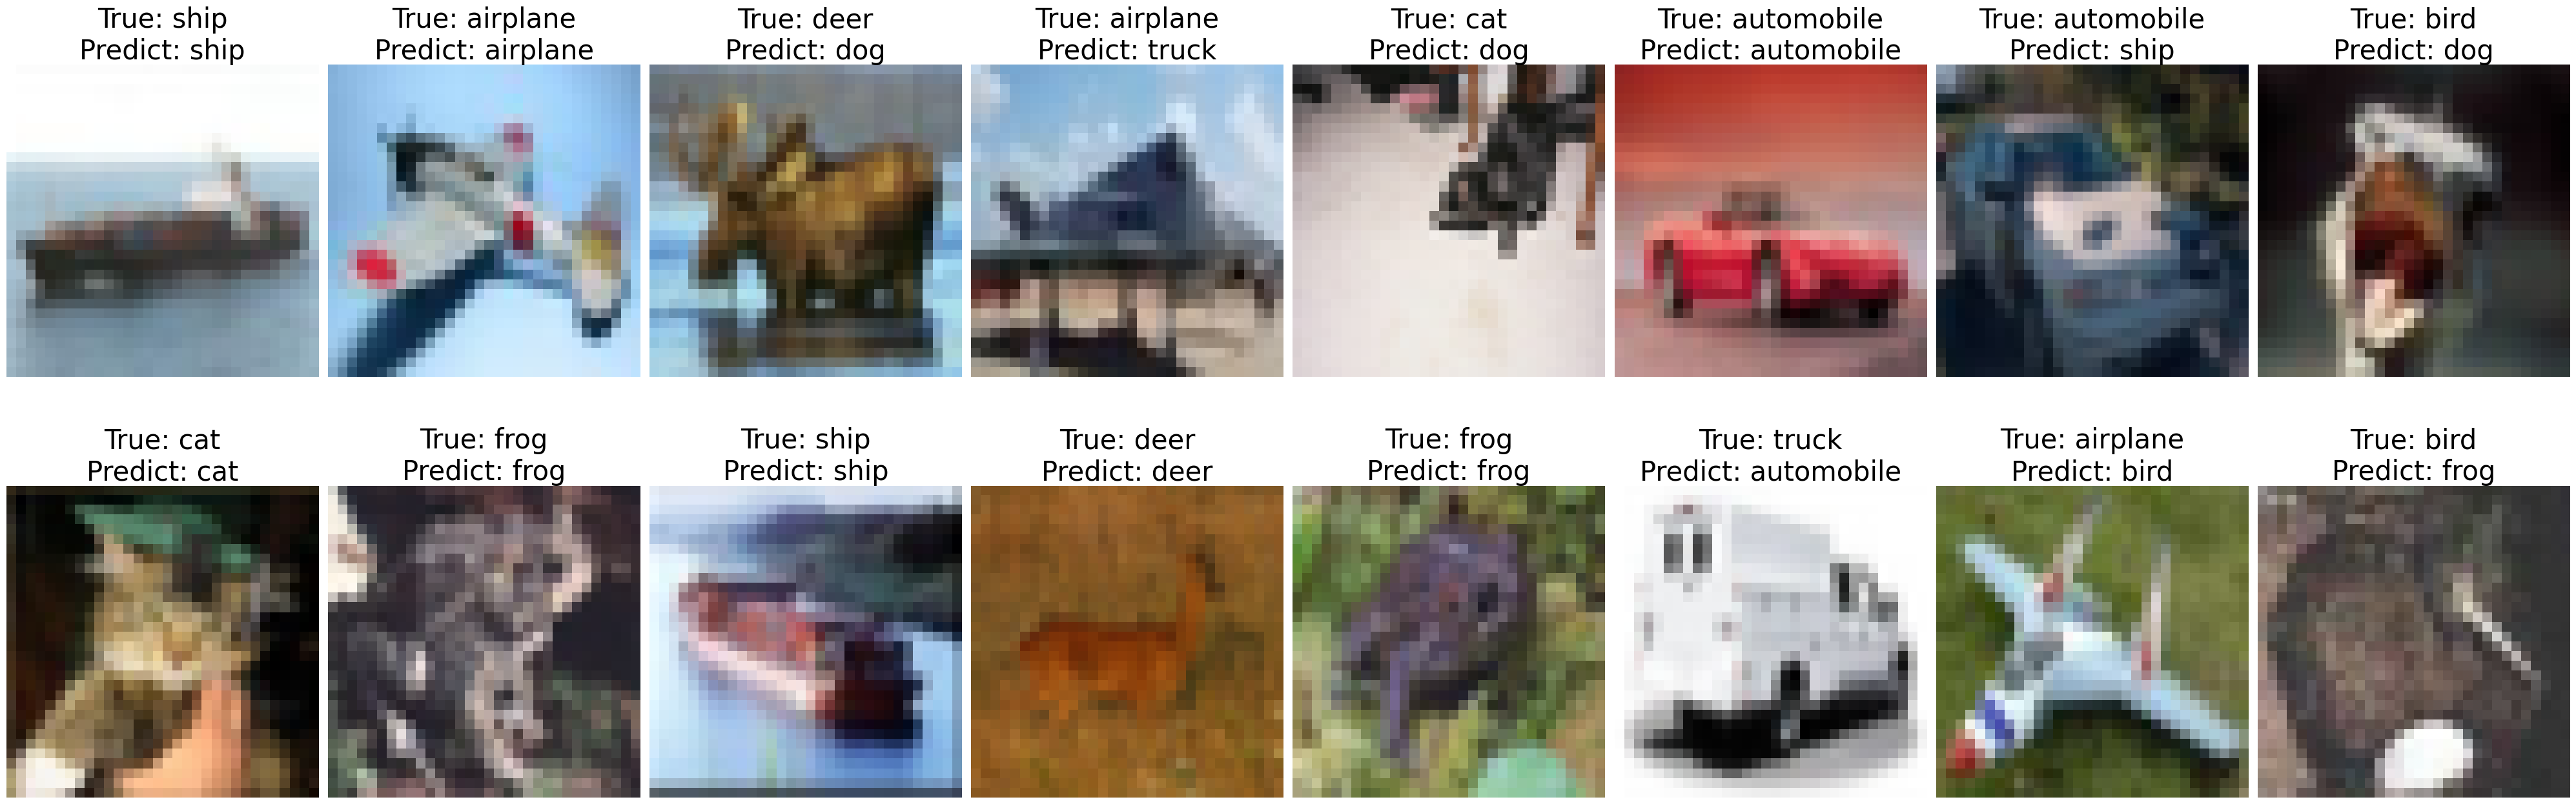

In [45]:
draw_image_predicts(conv_model, examples, transform, true_labels)